## 一、先想清楚：这个项目要回答什么

**核心问题**：给网络 "增加容量" 时，**加宽**（一层塞很多神经元）和**加深**（多堆几层）哪个更划算？

**为什么要比 "参数量"**：因为加宽和加深都会增加参数。如果不看参数量，光说 "深的拟合好"，不公平 —— 深的多花了参数。所以要在**相近 / 可比的参数量下比较拟合效果**，这才是工程上该问的问题。

In [10]:
import numpy as np
import matplotlib.pyplot as plt

def f_true(x):
    return np.sin(3 * x) + 0.5 * x

np.random.seed(0)
x_train = np.random.uniform(-3, 3, size=(1000, 1))
y_train = f_true(x_train) + 0.05 * np.random.randn(1000, 1)
x_eval = np.linspace(-3, 3, 500).reshape(-1, 1)
y_eval = f_true(x_eval)

In [11]:
def init_params(layer_sizes, seed=0):
    np.random.seed(seed)
    W_list, b_list = [], []
    for i in range(len(layer_sizes) - 1):
        W = np.random.randn(layer_sizes[i], layer_sizes[i+1]) * 0.1
        b = np.zeros((1, layer_sizes[i+1]))
        W_list.append(W); b_list.append(b)
    return W_list, b_list

def forward(X, W_list, b_list):
    A = X
    cache = [A]
    L = len(W_list)
    for i in range(L):
        Z = A @ W_list[i] + b_list[i]
        if i < L - 1:
            A = np.tanh(Z)
        else:
            A = Z
        cache.append(A)
    return A, cache

def backward(y, Yhat, cache, W_list):
    N = y.shape[0]
    grads_W = [None] * len(W_list)
    grads_b = [None] * len(W_list)
    dZ = 2.0 / N * (Yhat - y)
    for i in reversed(range(len(W_list))):
        A_prev = cache[i]
        grads_W[i] = A_prev.T @ dZ
        grads_b[i] = np.sum(dZ, axis=0, keepdims=True)
        if i > 0:
            dA_prev = dZ @ W_list[i].T
            dZ = dA_prev * (1 - cache[i]**2)
    return grads_W, grads_b

In [ ]:
def mse_loss(Yhat, y):
    return np.mean((Yhat - y)**2)

def train(X, y, layer_sizes, lr=0.05, epochs=3000, seed=0):
    W_list, b_list = init_params(layer_sizes, seed=seed)
    losses = []
    for _ in range(epochs):
        Yhat, cache = forward(X, W_list, b_list)
        loss = mse_loss(Yhat, y)
        grads_W, grads_b = backward(y, Yhat, cache, W_list)
        for i in range(len(W_list)):
            W_list[i] -= lr * grads_W[i]
            b_list[i] -= lr * grads_b[i]
        losses.append(loss)
    return W_list, b_list, losses

def count_params(W_list, b_list):
    return sum(w.size for w in W_list) + sum(b.size for b in b_list)

In [13]:
configs = {
    'wide-shallow-64':  [1, 64, 1],
    'deep-4x16':        [1, 16, 16, 16, 16, 1],
    'wide-shallow-288': [1, 288, 1],
    'deep-4x8':         [1, 8, 8, 8, 8, 1],
}

results = {}
for name, sizes in configs.items():
    W_list, b_list, losses = train(x_train, y_train, sizes, lr=0.05, epochs=3000, seed=0)
    results[name] = (W_list, b_list, losses)
    print(f"{name:<20} params={count_params(W_list,b_list):<6} final_loss={losses[-1]:.6f}")

wide-shallow-64      params=193    final_loss=0.423834
deep-4x16            params=865    final_loss=0.491040
wide-shallow-288     params=865    final_loss=0.409242
deep-4x8             params=241    final_loss=0.499227


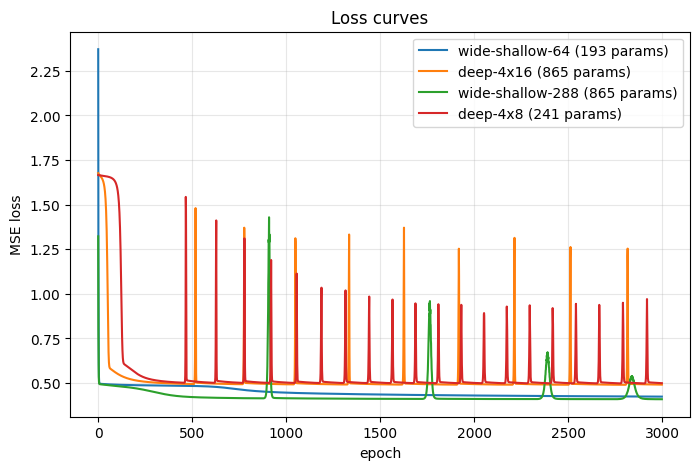

In [14]:
plt.figure(figsize=(8, 5))
for name, (W_list, b_list, losses) in results.items():
    plt.plot(losses, label=f"{name} ({count_params(W_list,b_list)} params)")
plt.xlabel('epoch'); plt.ylabel('MSE loss')
plt.legend(); plt.grid(alpha=0.3)
plt.title('Loss curves')
plt.show()

In [15]:
print(f"{'network':<20}{'params':<8}{'eval_mse':<10}")
for name, (W_list, b_list, losses) in results.items():
    Yhat_eval, _ = forward(x_eval, W_list, b_list)
    err = mse_loss(Yhat_eval, y_eval)
    print(f"{name:<20}{count_params(W_list,b_list):<8}{err:<10.6f}")

network             params  eval_mse  
wide-shallow-64     193     0.431762  
deep-4x16           865     0.498332  
wide-shallow-288    865     0.416538  
deep-4x8            241     0.506787  


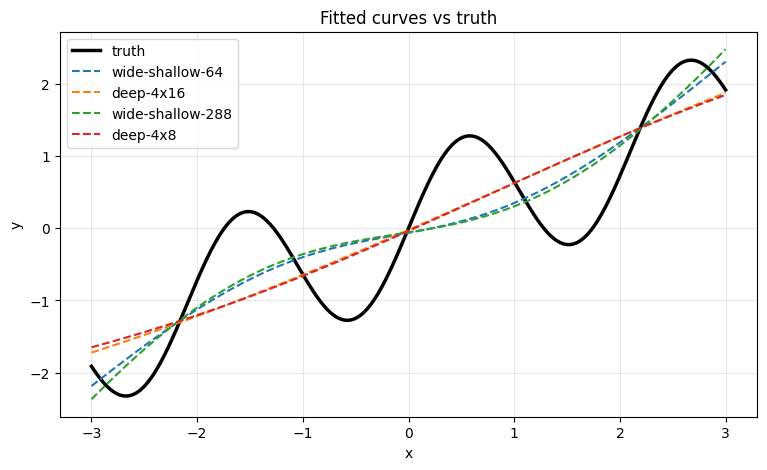

In [16]:
plt.figure(figsize=(9, 5))
plt.plot(x_eval, y_eval, 'k-', lw=2.5, label='truth')
for name, (W_list, b_list, losses) in results.items():
    Yhat_eval, _ = forward(x_eval, W_list, b_list)
    plt.plot(x_eval, Yhat_eval, '--', label=name)
plt.xlabel('x'); plt.ylabel('y')
plt.legend(); plt.grid(alpha=0.3)
plt.title('Fitted curves vs truth')
plt.show()